# LAB 3
En este lab repasaremos los conceptos vistos en la clase 4 Frontera Eficiente

## Bibliotecas a importar

* yfinance: la usaremos para descargar información
* numpy: la usaremos para realizar diversas operaciones matemáticas
* pandas: la usaremos para realizar cálculos con vectores
* analisis_portafolios: nuestra biblioteca del curso que tendrá funciones para los procedimientos vistos en clase

In [24]:
import yfinance as yf
import numpy as np
import pandas as pd
import analisis_portafolios as ap

## Descargamos la información a analizar
En este lab trabajaremos con varias empresas de sectores distintos, pues queremos estudiar cómo se comportan juntas.

In [25]:
tickers = ["AAPL", "MSFT", "JPM", "KO", "XOM"] # tickers de las acciones a analizar
fecha_inicio = "2025-01-01" # fecha de inicio para descargar
fecha_fin = "2025-12-31" # fecha final para descargar

In [26]:
datos = yf.download(tickers, start=fecha_inicio, end=fecha_fin)

[*********************100%***********************]  4 of 5 completed


In [27]:
# extraemos los precios de cierre de todas las empresas
precios_cierre = datos["Close"]
precios_cierre.head()

Ticker,AAPL,JPM,KO,MSFT,XOM
Date,,,,,
2025-01-02,242.093140,230.583786,58.923302,412.895325,101.475342
2025-01-03,241.606674,233.735092,58.837547,417.600555,101.995445
2025-01-06,243.234833,232.595551,57.941883,422.039490,101.881966
2025-01-07,240.464951,234.836029,57.970463,416.633881,102.837036
2025-01-08,240.951401,234.797394,58.799427,418.794128,101.116013


<Axes: xlabel='Date'>

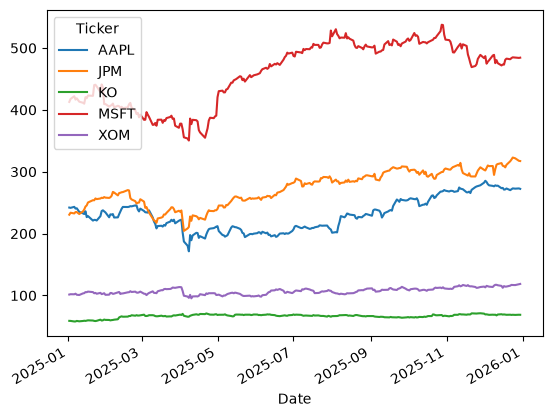

In [28]:
# visualizamos los precios de cierre
precios_cierre.plot()

## Rendimientos

Calculamos los rendimientos porcentuales igual que en los labs anteriores. Ahora obtenemos una columna por empresa.

In [29]:
rend_simple = precios_cierre.pct_change().dropna()

In [30]:
rend_simple.head()

Ticker,AAPL,JPM,KO,MSFT,XOM
Date,,,,,
2025-01-03,-0.002009,0.013667,-0.001455,0.011396,0.005125
2025-01-06,0.006739,-0.004875,-0.015223,0.010630,-0.001113
2025-01-07,-0.011388,0.009633,0.000493,-0.012808,0.009374
2025-01-08,0.002023,-0.000165,0.014300,0.005185,-0.016735
2025-01-10,-0.024104,-0.013408,-0.010371,-0.013214,-0.003647


## Riesgo y rendimiento por activo

Las funciones del Lab 1 también funcionan con varias columnas a la vez: nos regresan un valor por empresa.

In [31]:
# rendimiento esperado anualizado de cada activo
rend_esperado = ap.rendimiento_anualizado(rend_simple)
rend_esperado

Ticker
AAPL    0.127072
JPM     0.383215
KO      0.169417
MSFT    0.176222
XOM     0.171807
dtype: float64

In [32]:
# volatilidad anualizada de cada activo
ap.volatilidad_anualizada(rend_simple)

Ticker
AAPL    0.325256
JPM     0.249451
KO      0.175680
MSFT    0.243322
XOM     0.234978
dtype: float64

## Covarianza y correlación

La **covarianza** mide cómo se mueven juntos los rendimientos de dos activos:

$$ \sigma_{AB} = \frac{1}{n-1}\sum_{t=1}^{n}(R_{A,t}-\bar{R}_A)(R_{B,t}-\bar{R}_B) $$

La **correlación** es la covarianza estandarizada, por lo que siempre está entre $-1$ y $1$:

$$ \rho_{AB} = \frac{\sigma_{AB}}{\sigma_A \, \sigma_B} $$

### Matriz de covarianzas
Al igual que la volatilidad, la covarianza se anualiza multiplicando por $p=252$.

In [33]:
cov = ap.matriz_covarianza_anualizada(rend_simple)
cov

Ticker,AAPL,JPM,KO,MSFT,XOM
Ticker,,,,,
AAPL,0.105792,0.041698,0.006111,0.038464,0.029098
JPM,0.041698,0.062226,0.003744,0.028786,0.020907
KO,0.006111,0.003744,0.030863,-0.005780,0.005234
MSFT,0.038464,0.028786,-0.005780,0.059205,0.010341
XOM,0.029098,0.020907,0.005234,0.010341,0.055214


**NOTA:** La diagonal de la matriz de covarianzas es la varianza anualizada de cada activo, es decir, la volatilidad anualizada al cuadrado.

In [34]:
# comprobamos: la raíz de la diagonal es la volatilidad anualizada
np.sqrt(np.diag(cov))

array([0.32525611, 0.24945105, 0.17567994, 0.24332162, 0.23497753])

### Matriz de correlación

In [35]:
rend_simple.corr()

Ticker,AAPL,JPM,KO,MSFT,XOM
Ticker,,,,,
AAPL,1.000000,0.513925,0.106953,0.486009,0.380720
JPM,0.513925,1.000000,0.085430,0.474251,0.356688
KO,0.106953,0.085430,1.000000,-0.135210,0.126781
MSFT,0.486009,0.474251,-0.135210,1.000000,0.180870
XOM,0.380720,0.356688,0.126781,0.180870,1.000000


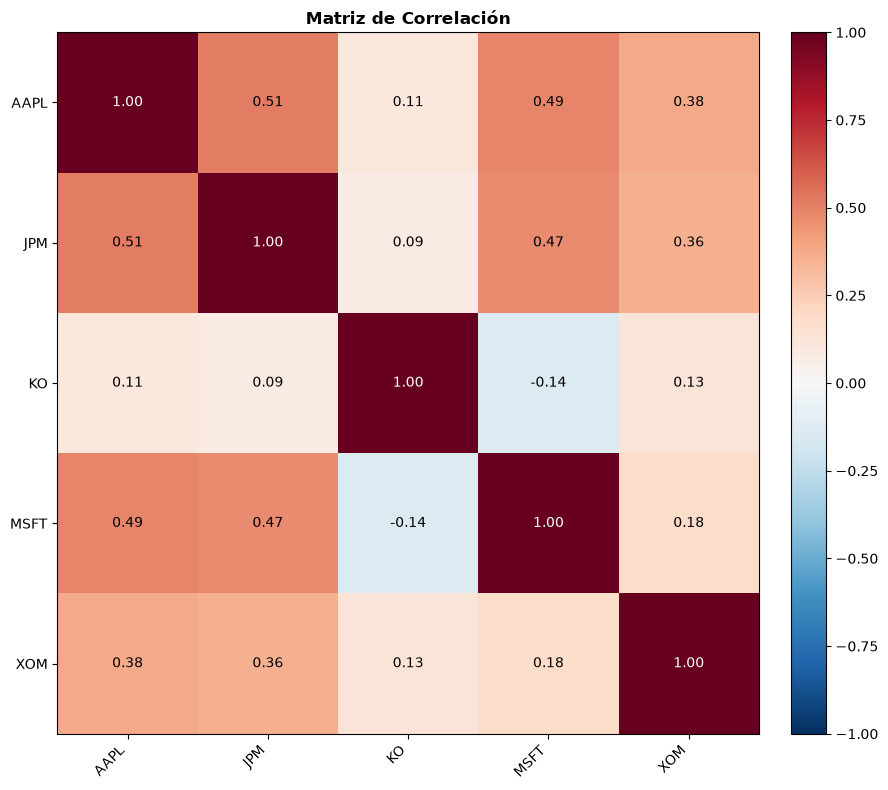

In [36]:
# Visualizamos
fig, ax = ap.plot_correlacion(rend_simple)

Entre menor sea la correlación entre dos activos, mayor será el beneficio de combinarlos en un portafolio (**efecto diversificación**).

## Portafolio de dos activos

Si invertimos una proporción $w_1$ en el activo 1 y $w_2 = 1 - w_1$ en el activo 2:

$$ \mu_p = w_1 \mu_1 + w_2 \mu_2 $$

$$ \sigma_p^2 = w_1^2\sigma_1^2 + w_2^2\sigma_2^2 + 2w_1w_2\sigma_{12} $$

En forma matricial, para cualquier número de activos:

$$ \mu_p = w^\top \mu \qquad \sigma_p = \sqrt{w^\top \Sigma \, w} $$

In [37]:
# elegimos dos activos
activos_2 = ["KO", "MSFT"]
rend_esperado_2 = rend_esperado[activos_2]
cov_2 = cov.loc[activos_2, activos_2]

In [38]:
# portafolio 50/50
pesos_50 = np.array([0.5, 0.5])
print(f"Rendimiento: {ap.rendimiento_portafolio(pesos_50, rend_esperado_2):.2%}")
print(f"Volatilidad: {ap.volatilidad_portafolio(pesos_50, cov_2):.2%}")

Rendimiento: 17.28%
Volatilidad: 14.01%


Comparemos contra la volatilidad de cada activo por separado. La volatilidad del portafolio es menor que el promedio de las volatilidades individuales porque la correlación es menor a 1.

In [39]:
vol_2 = np.sqrt(np.diag(cov_2))
print(f"Promedio de volatilidades individuales: {vol_2.mean():.2%}")

Promedio de volatilidades individuales: 20.95%


### Frontera de dos activos
Recorremos todas las combinaciones de pesos posibles entre los dos activos.

In [40]:
frontera_2 = ap.frontera_2_activos(rend_esperado_2, cov_2)
frontera_2.head()

,Peso Activo 1,Rendimiento,Volatilidad
0,0.000000,0.176222,0.243322
1,0.020408,0.176083,0.237898
2,0.040816,0.175944,0.232529
3,0.061224,0.175805,0.227220
4,0.081633,0.175666,0.221975


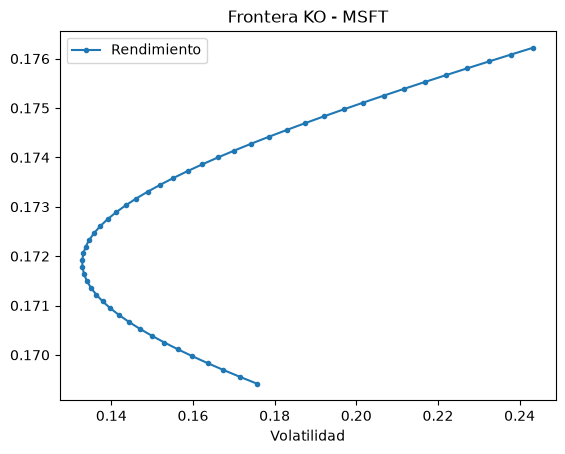

In [41]:
ax = frontera_2.plot(x="Volatilidad", y="Rendimiento", style=".-", title=f"Frontera {activos_2[0]} - {activos_2[1]}")

## Utilizar funciones con mis propios datos

Si queremos utilizar las funciones con datos capturados manualmente sólo tenemos que escribirlos en el formato adecuado.

Supongamos que tenemos dos activos con los siguientes datos anuales:
* Activo A: rendimiento esperado 10%, volatilidad 15%
* Activo B: rendimiento esperado 6%, volatilidad 8%
* Correlación entre A y B: 0.2

In [42]:
rend_esp_ej = pd.Series([0.10, 0.06], index=["A", "B"])
vol_ej = np.array([0.15, 0.08])
rho = 0.2

In [43]:
# construimos la matriz de covarianzas: cov_AB = rho * vol_A * vol_B
cov_AB = rho * vol_ej[0] * vol_ej[1]
cov_ej = pd.DataFrame(
    [[vol_ej[0]**2, cov_AB],
     [cov_AB, vol_ej[1]**2]],
    index=["A", "B"], columns=["A", "B"]
)
cov_ej

,A,B
A,0.0225,0.0024
B,0.0024,0.0064


In [44]:
# portafolio 60% A, 40% B
pesos_ej = np.array([0.6, 0.4])
print(f"Rendimiento: {ap.rendimiento_portafolio(pesos_ej, rend_esp_ej):.2%}")
print(f"Volatilidad: {ap.volatilidad_portafolio(pesos_ej, cov_ej):.2%}")

Rendimiento: 8.40%
Volatilidad: 10.14%


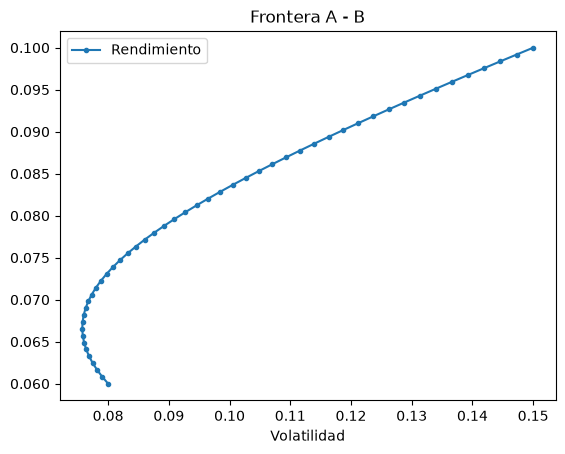

In [45]:
ax = ap.frontera_2_activos(rend_esp_ej, cov_ej).plot(x="Volatilidad", y="Rendimiento", style=".-", title="Frontera A - B")